# Decision Tree Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Decision Trees are non-parametric supervised learning algorithms capable of capturing complex and non-linear relationships between predictor variables and the target variable.

This notebook develops a Decision Tree classifier using the PCA-transformed applicant dataset to predict loan default.

The objectives are to:

- Train a Decision Tree classifier.
- Predict loan default.
- Evaluate classification performance.
- Interpret the learned decision rules.
- Analyze feature importance.
- Compare the model with Logistic Regression.

# Import Required Libraries

The following libraries are used for training, evaluating, and visualizing the Decision Tree classifier.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets created during feature engineering are loaded for model development.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train Decision Tree Model

A Decision Tree classifier is trained using the training dataset.

In [3]:
# ============================================================
# Train Model
# ============================================================

tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=20,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


# Generate Predictions

The trained Decision Tree model is used to predict both class labels and default probabilities.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = tree_model.predict(X_test)

y_prob = tree_model.predict_proba(X_test)[:,1]

# Model Evaluation

The classifier is evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.917971
1,Precision,0.142857
2,Recall,0.003223
3,F1 Score,0.006303
4,ROC AUC,0.686772


# Confusion Matrix

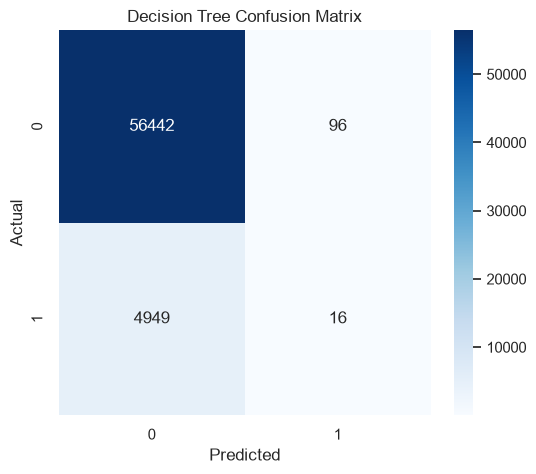

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

# Classification Report

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.14      0.00      0.01      4965

    accuracy                           0.92     61503
   macro avg       0.53      0.50      0.48     61503
weighted avg       0.86      0.92      0.88     61503



# ROC Curve

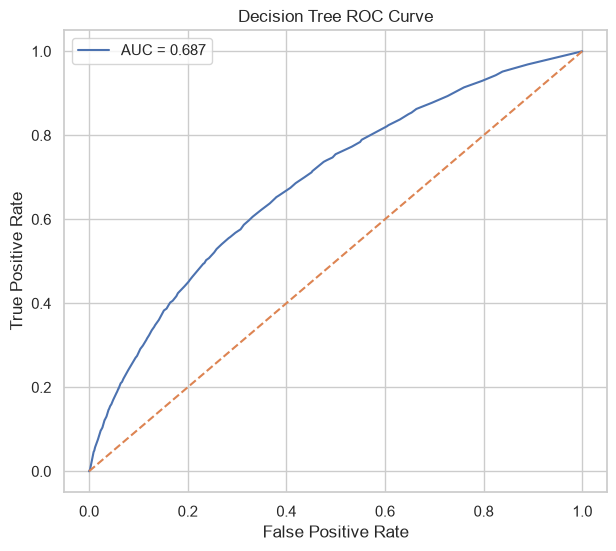

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Feature Importance

Decision Trees estimate the importance of each input feature based on how much it contributes to reducing node impurity.

Although PCA components are transformed features rather than original variables, examining their relative importance still provides insight into which components contribute most to the model's decisions.

In [9]:
feature_importance = (
    pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": tree_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

feature_importance.head(15)

,Feature,Importance
8,PC9,0.192088
7,PC8,0.124468
17,PC18,0.112537
2,PC3,0.068454
19,PC20,0.067520
1,PC2,0.056902
5,PC6,0.038688
10,PC11,0.037913
28,PC29,0.033418
30,PC31,0.020932


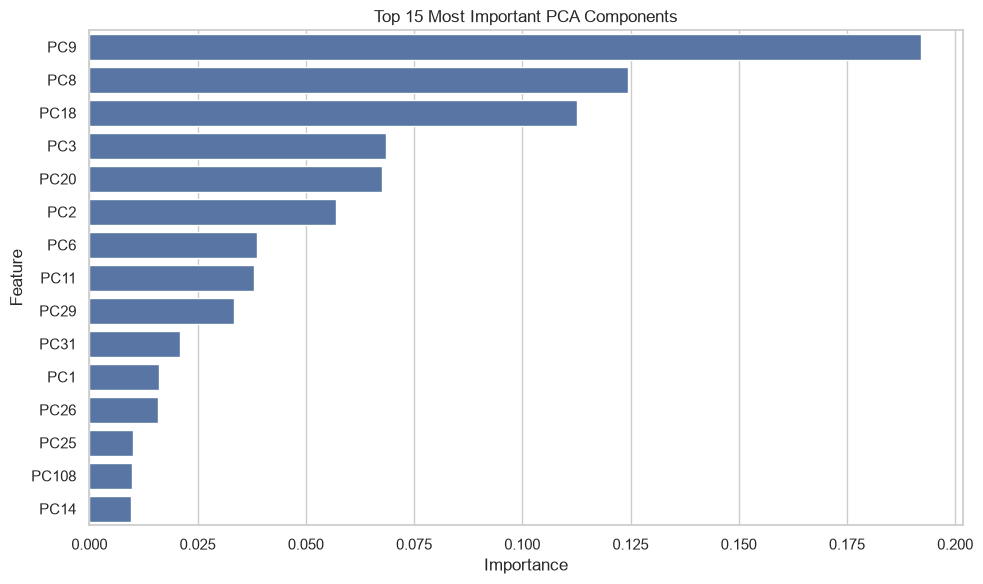

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Most Important PCA Components")

plt.tight_layout()

plt.show()

# Decision Tree Visualization

The first few levels of the trained Decision Tree are visualized to illustrate how the classifier partitions the feature space.

Only the upper levels of the tree are displayed to maintain readability.

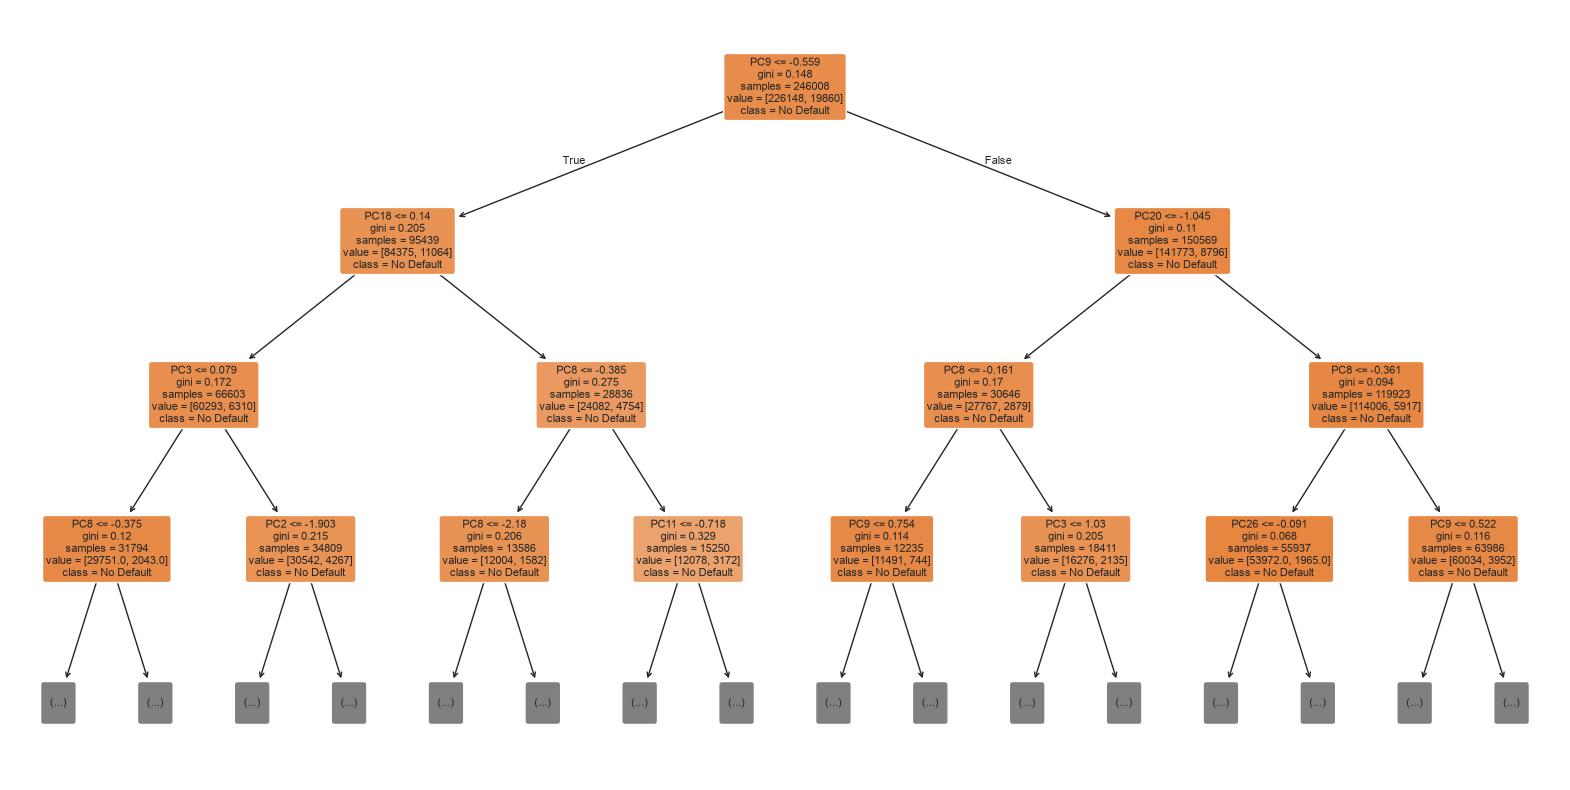

In [11]:
plt.figure(figsize=(20,10))

plot_tree(
    tree_model,
    max_depth=3,
    filled=True,
    rounded=True,
    feature_names=X_train.columns,
    class_names=["No Default", "Default"],
    fontsize=8
)

plt.show()

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [13]:
# ============================================================
# Save Decision Tree Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    tree_model,
    MODEL_DIR / "decision_tree_model.pkl"
)

print("Decision Tree model saved successfully.")

Decision Tree model saved successfully.


# Save Model Performance

In [12]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Decision Tree Classifier"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Decision Tree Classifier,0.917971,0.142857,0.003223,0.006303,0.686772,96,4949,16,56442


# Conclusion

The Decision Tree classifier was successfully trained and evaluated using the PCA-transformed dataset.

## Key Outcomes

- A Decision Tree model was developed to classify loan applicants based on their probability of default.
- Model performance was evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- The confusion matrix and ROC curve provided insight into the classifier's predictive performance.
- Feature importance analysis identified the principal components that contributed most to the model's decisions.
- The results have been saved for comparison with the remaining classification models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 08 – K-Nearest Neighbors (KNN) Classifier**